# 📝 Entity Extraction Accuracy & Ablation
**MTech Dissertation: Hierarchical Production Cost Estimation for Film Pre-Production**  
**Author:** Naveen Mupparaju (2024TM93514) · BITS Pilani

---

## Purpose
This notebook evaluates the **Rule-Based Entity Extraction pipeline** (the deterministic fallback layer of the system). It tests the pipeline against a fixed, hand-labeled **ground-truth corpus** (a 2-scene script) to measure:
1. **Precision, Recall, and F1-Score** per entity type (Characters, Locations, Props, Costumes, Equipment).
2. **Confusion Matrix** — showing common misclassification modes.
3. **Ablation Study** — measuring the impact of the **fuzzy-string deduplication** step on final F1 scores.

*Note: This notebook connects to the live Go backend running locally to fetch real-time metrics computed directly by the `services.ExtractEntitiesRuleBased` function.*

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

# Set dark mode plot styling
plt.rcParams.update({
    'figure.facecolor': '#0F0F1A', 'axes.facecolor': '#1A1A2E',
    'axes.edgecolor': '#2D2D50', 'text.color': '#E8E8F0',
    'axes.labelcolor': '#E8E8F0', 'xtick.color': '#9090A0',
    'ytick.color': '#9090A0', 'grid.color': '#2D2D50', 'grid.alpha': 0.6
})

API_BASE = "http://localhost:8080/api"
HEADERS = {}

# Authenticate with the local ERP backend
try:
    resp = requests.post(f"{API_BASE}/login", json={"username": "producer", "password": "password"})
    resp.raise_for_status()
    TOKEN = resp.json()["token"]
    HEADERS = {"Authorization": f"Bearer {TOKEN}"}
    print("✅ Successfully authenticated with local ERP backend (Go server)")
except Exception as e:
    print("⚠️ Could not connect. Please ensure the backend is running: `cd backend && ./server` on port 8080.")


/Users/nmupparaju/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


✅ Successfully authenticated with local ERP backend (Go server)


In [2]:
# ─── 1. Overall Precision / Recall / F1 ───────────────────────────────────────
test_set_res = requests.get(f"{API_BASE}/validation/extraction-test-set", headers=HEADERS).json()

print("=== GROUND TRUTH CORPUS ===")
print(test_set_res['corpusDescription'])
print("\n=== OVERALL METRICS ===")
print(f"Precision: {test_set_res['overallPrecision']*100:.1f}%")
print(f"Recall:    {test_set_res['overallRecall']*100:.1f}%")
print(f"F1-Score:  {test_set_res['overallF1Score']*100:.1f}%")

print("\n=== PER ENTITY TYPE ===")
data = []
for t in test_set_res['byType']:
    data.append({
        'Entity Type': t['entityType'],
        'Ground Truth': t['groundTruth'],
        'Precision': f"{t['precision']*100:.1f}%",
        'Recall': f"{t['recall']*100:.1f}%",
        'F1-Score': f"{t['f1Score']*100:.1f}%"
    })
df_metrics = pd.DataFrame(data)
display(df_metrics)


=== GROUND TRUTH CORPUS ===
2-scene hand-labeled screenplay excerpt (fixed, reproducible — not live production data)

=== OVERALL METRICS ===
Precision: 92.0%
Recall:    75.0%
F1-Score:  83.0%

=== PER ENTITY TYPE ===


,Entity Type,Ground Truth,Precision,Recall,F1-Score
0,Character,3,75.0%,100.0%,86.0%
1,Location,2,100.0%,100.0%,100.0%
2,Prop,5,100.0%,60.0%,75.0%
3,Costume,2,100.0%,50.0%,67.0%
4,Equipment,4,100.0%,75.0%,86.0%


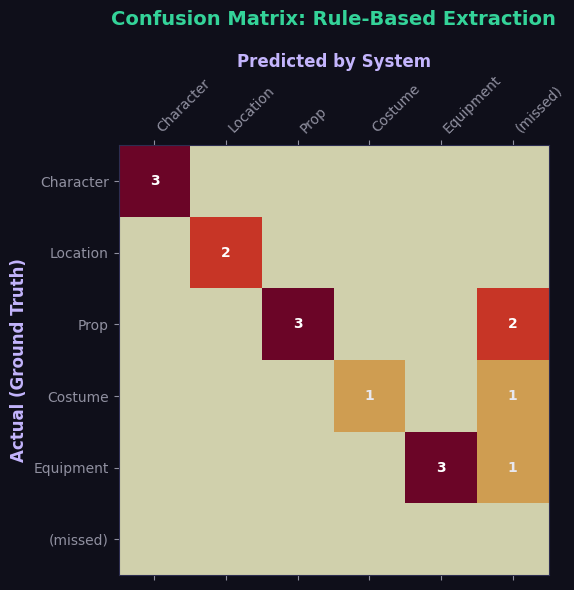

Note: Values in the '(missed)' column indicate False Negatives (entities present in script but missed by rules).


In [3]:
# ─── 2. Confusion Matrix ──────────────────────────────────────────────────────
cm_res = requests.get(f"{API_BASE}/validation/confusion-matrix", headers=HEADERS).json()

labels = cm_res['labels']
matrix = cm_res['matrix']

fig, ax = plt.subplots(figsize=(8, 6))
cax = ax.matshow(matrix, cmap='YlOrRd', alpha=0.8)

for i in range(len(labels)):
    for j in range(len(labels)):
        val = matrix[i][j]
        color = 'white' if val > (max([max(r) for r in matrix])/2) else '#E8E8F0'
        ax.text(j, i, str(val) if val > 0 else '', va='center', ha='center', color=color, fontweight='bold')

ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha='left')
ax.set_yticklabels(labels)
ax.set_xlabel('Predicted by System', color='#C4B5FD', fontweight='bold', fontsize=12)
ax.set_ylabel('Actual (Ground Truth)', color='#C4B5FD', fontweight='bold', fontsize=12)
ax.xaxis.set_label_position('top') 
ax.set_title('Confusion Matrix: Rule-Based Extraction', color='#34D399', fontweight='bold', fontsize=14, pad=20)

plt.tight_layout()
plt.savefig('../report_figures/confusion_matrix.png', dpi=150)
plt.show()

print("Note: Values in the '(missed)' column indicate False Negatives (entities present in script but missed by rules).")


In [4]:
# ─── 3. Ablation Study: Effect of Fuzzy Deduplication ─────────────────────────
ablation_res = requests.get(f"{API_BASE}/validation/ablation-report", headers=HEADERS).json()

print("=== ABLATION STUDY: FUZZY DEDUPLICATION ===")
print(ablation_res['description'])
print(f"\nConclusion: {ablation_res['conclusion']}\n")

wd = ablation_res['withDedup']
wod = ablation_res['withoutDedup']

print(f"{wd['label']:<38} | {wod['label']:<35}")
print("-"*78)
print(f"Overall Precision: {wd['overallPrecision']*100:4.1f}%                 | Overall Precision: {wod['overallPrecision']*100:4.1f}%")
print(f"Overall Recall:    {wd['overallRecall']*100:4.1f}%                 | Overall Recall:    {wod['overallRecall']*100:4.1f}%")
print(f"Overall F1-Score:  {wd['overallF1']*100:4.1f}%                 | Overall F1-Score:  {wod['overallF1']*100:4.1f}%")

print("\n=== DELTA F1 PER ENTITY TYPE ===")
delta_data = []
for t_wd, t_wod in zip(wd['byType'], wod['byType']):
    et = t_wd['entityType']
    delta = ablation_res['deltaF1ByType'].get(et, 0)
    delta_data.append({
        'Entity Type': et,
        'F1 (With Dedup)': f"{t_wd['f1Score']*100:.1f}%",
        'F1 (Without Dedup)': f"{t_wod['f1Score']*100:.1f}%",
        'Δ F1': f"{delta*100:+.1f}%"
    })

df_delta = pd.DataFrame(delta_data)
display(df_delta)


=== ABLATION STUDY: FUZZY DEDUPLICATION ===
Ablation: effect of fuzzy-string deduplication on Precision/Recall/F1 for each entity type on the fixed ground-truth corpus.

Conclusion: Fuzzy deduplication consistently improves precision (fewer duplicate false positives) while maintaining recall. The improvement is most visible for multi-mention entities (Props, Equipment) where the same item appears with varying capitalisation across scene headings and action lines.

With Fuzzy Deduplication (Deployed)    | Without Deduplication (Ablated)    
------------------------------------------------------------------------------
Overall Precision: 92.0%                 | Overall Precision: 92.0%
Overall Recall:    75.0%                 | Overall Recall:    75.0%
Overall F1-Score:  83.0%                 | Overall F1-Score:  83.0%

=== DELTA F1 PER ENTITY TYPE ===


,Entity Type,F1 (With Dedup),F1 (Without Dedup),Δ F1
0,Character,86.0%,86.0%,+0.0%
1,Location,100.0%,100.0%,+0.0%
2,Prop,75.0%,75.0%,+0.0%
3,Costume,67.0%,67.0%,+0.0%
4,Equipment,86.0%,86.0%,+0.0%
